In [1]:
import pandas as pd
import numpy as np


import xgboost as xgb
import joblib


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mutual_info_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    f1_score
) # Validation

import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
train = pd.read_csv("train.csv")
econ = pd.read_csv("economic_indicators.csv")

In [3]:
train.columns = train.columns.str.lower().str.replace(" ", "_", regex=False)
econ.columns = econ.columns.str.lower().str.replace(" ", "_", regex=False)


# Columns to exclude from model features
exclude_cols = ['id', 'target']

# Identifiers that should not automatically be treated as continuous numbers
id_cols = ['customer_id', 'country_id', 'tbl_loan_id', 'lender_id']

# Dates
date_cols = ['disbursement_date', 'due_date']
# Convert dates
for col in date_cols:
    train[col] = pd.to_datetime(train[col], errors='coerce')

for category in ["country_id", "loan_type", "new_versus_repeat"]:
    train[category] = train[category].str.lower().str.replace(" ", "_")

for cat in ["country", "indicator"]:
    econ[cat] = econ[cat].str.lower().str.replace(" ", "_")

# date-based features
train['loan_year'] = train["disbursement_date"].dt.year
train['loan_month'] = train["disbursement_date"].dt.month

# financial features
train["interest_amount"] = train.total_amount_to_repay - train.total_amount
train["repayment_ratio"] = train.total_amount_to_repay / train.total_amount


# Handling Outliers: use np.log1p()
train["duration_log"] = np.log1p(train["duration"])
train["total_amount_log"] = np.log1p(train['total_amount'])


In [4]:
# Prepare econ for merging
# Identify year columns
year_cols = [col for col in econ.columns if col.startswith('yr')]

# Convert wide to long format
econ_long = econ.melt(
    id_vars=['country', 'indicator'],
    value_vars=year_cols,
    var_name='year',
    value_name='economic_value'
)

# Extract numeric year
econ_long['year'] = econ_long['year'].str.replace('yr', '').astype(int)

# Pivot economic indicators into columns
econ_wide = econ_long.pivot_table(
    index=['country', 'year'],
    columns='indicator',
    values='economic_value',
    aggfunc='first'
).reset_index()

# Remove the columns index name
econ_wide.columns.name = None
# econ_wide[econ_wide.country == "kenya"]

In [5]:
train.rename(columns={'country_id': 'country'}, inplace=True)

# Merge economic indicators using country and year
combined = train.merge(
    econ_wide,
    left_on=['country', 'loan_year'],
    right_on=['country', 'year'],
    how='left',
    validate='many_to_one'
)

# Remove the redundant year column
combined.drop(columns=['year'], inplace=True)
# combined.head()

In [6]:

# Define categorical and numerical columns
# Categorical features
categorical_cols = [
    'country',
    'loan_type',
    'new_versus_repeat',
]
# Add lender_id only if you want to test its predictive value
# categorical_cols.append('lender_id')
categorical_cols = [
    col for col in categorical_cols
    if col in combined.columns
]
# Exclude target and identifier columns from numerical features
exclude_cols = [
    'target',
    'id',
    'customer_id',
    'tbl_loan_id',
    'lender_id',
    'duration',# use the log variant
    'total_amount', # use the log variant
    'average_precipitation_in_depth_(mm_per_year)', # produce NaN and have a low correlation to target
    'fossil_fuel_energy_consumption_(%_of_total)', # produce NaN and have a low correlation to target
]


numerical_cols = [
    col for col in combined.select_dtypes(include='number').columns
    if col not in exclude_cols
]
print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)


Categorical features: ['country', 'loan_type', 'new_versus_repeat']
Numerical features: ['total_amount_to_repay', 'amount_funded_by_lender', 'lender_portion_funded', 'lender_portion_to_be_repaid', 'loan_year', 'loan_month', 'interest_amount', 'repayment_ratio', 'duration_log', 'total_amount_log', 'deposit_interest_rate_(%)', 'inflation,_consumer_prices_(annual_%)', 'interest_rate_spread_(lending_rate_minus_deposit_rate,_%)', 'lending_interest_rate_(%)', 'official_exchange_rate_(lcu_per_us$,_period_average)', 'real_interest_rate_(%)', 'unemployment_rate']


In [7]:
def mutual_info_target_score(series):
    return mutual_info_score(series, train.target)

mi = train[categorical_cols].apply(mutual_info_target_score)
mi.sort_values(ascending=False)
print(f"mutual info score:\n {mi}\n")

ans = {}
for column in numerical_cols:
    corr = combined[column].corr(combined['target'])
    key = f"{column}"
    ans[key] = corr
print(f"numerical_columns correlation to target:\n {ans}\n")

mutual info score:
 country              0.000000
loan_type            0.015103
new_versus_repeat    0.002525
dtype: float64

numerical_columns correlation to target:
 {'total_amount_to_repay': np.float64(0.07385302532419592), 'amount_funded_by_lender': np.float64(0.10377741175311125), 'lender_portion_funded': np.float64(0.04579732878048301), 'lender_portion_to_be_repaid': np.float64(0.11072786410708564), 'loan_year': np.float64(0.1254021678337026), 'loan_month': np.float64(-0.06880578596760357), 'interest_amount': np.float64(0.06295584305396335), 'repayment_ratio': np.float64(0.6501951337514946), 'duration_log': np.float64(0.21559463450276128), 'total_amount_log': np.float64(0.06842251219484996), 'deposit_interest_rate_(%)': np.float64(0.1051029177551162), 'inflation,_consumer_prices_(annual_%)': np.float64(-0.08629764814697098), 'interest_rate_spread_(lending_rate_minus_deposit_rate,_%)': np.float64(-0.1044864769123655), 'lending_interest_rate_(%)': np.float64(0.10547978790387627), '

In [8]:
# Split off the test set (20%)
df_full_train, df_test = train_test_split(
    combined,
    test_size=0.2,
    random_state=1,
    stratify=combined['target']
)

# Split remaining 80% into 60% train and 20% validation
df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1,
    stratify=df_full_train['target']
)

# Reset indices
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)


y_full_train = df_full_train['target'].values
y_train = df_train['target'].values
y_val = df_val['target'].values
y_test = df_test['target'].values

del df_full_train['target']
del df_train['target']
del df_val['target']
del df_test['target']



X_full_train = df_full_train[numerical_cols + categorical_cols]
X_train = df_train[numerical_cols + categorical_cols]
X_val = df_val[numerical_cols + categorical_cols]
X_test = df_test[numerical_cols + categorical_cols]

In [9]:
# Create preprocessing pipelines
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
# Combine the pipelines
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_cols),
    ('categorical', categorical_pipeline, categorical_cols),
])


In [10]:
# logistic_regression
logistic_regression_score = {}

In [11]:
# Training final logistic regression model with hyperparametrized values
logistic_reg_C = 0.1
logistic_reg_class_weight = "balanced"


logistic_regression = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, C=logistic_reg_C, class_weight=logistic_reg_class_weight)),
])
logistic_regression.fit(X_full_train, y_full_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [12]:
# decision tree
decision_tree_score = {}

In [13]:
# Training final model with parameters
class_weight = None
criterion = 'entropy'
max_depth = 5
min_samples_leaf = 20
min_samples_split = 2

decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42,
                                          class_weight=class_weight,
                                          criterion=criterion,
                                          max_depth=max_depth,
                                          min_samples_leaf=min_samples_leaf,
                                          min_samples_split=min_samples_split)),
])

decision_tree.fit(X_full_train, y_full_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [14]:
# random forrest
random_forest_score = {}

In [15]:
# Training final model: Random Forest
class_weight = 'balanced'
max_depth = 20
max_features = 'sqrt'
min_samples_leaf = 2
min_samples_split = 2
n_estimators = 300

random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42,
                                          class_weight=class_weight,
                                          max_depth=max_depth,
                                          max_features=max_features,
                                          min_samples_leaf=min_samples_leaf,
                                          min_samples_split=min_samples_split,
                                          n_estimators=n_estimators,
                                          n_jobs=-1)),
])

random_forest.fit(X_full_train, y_full_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [16]:
# XGBoost
xgboost_score = {}

In [17]:
# Training final model: XGBoost
colsample_bytree = 1.0
learning_rate = 0.05
max_depth = 7
min_child_weight = 1
n_estimators = 200
scale_pos_weight = 1
subsample = 0.8


xgboost = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        random_state=42,
        n_jobs=-1,
        
        colsample_bytree = colsample_bytree,
        learning_rate=learning_rate,
        max_depth=max_depth,
        min_child_weight=min_child_weight,
        n_estimators=n_estimators,
        scale_pos_weight=scale_pos_weight,
        subsample=subsample,
        
        eval_metric='logloss'
    )),
])

xgboost.fit(X_full_train, y_full_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [18]:
print(f"logistic_regression_score: \n{logistic_regression_score}\n")
print(f"decision_tree_score: \n{decision_tree_score}\n")
print(f"random_forest_score: \n{random_forest_score}\n")
print(f"xgboost_score: \n{xgboost_score}\n")

logistic_regression_score: 
{}

decision_tree_score: 
{}

random_forest_score: 
{}

xgboost_score: 
{}



In [19]:
# # Evaluation metrics

# import numpy as np
# import pandas as pd

# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     roc_auc_score,
#     classification_report,
# )

# # Generate predictions
# y_pred = xgboost.predict(X_test)

# # Probabilities for the positive class (target = 1)
# y_prob = xgboost.predict_proba(X_test)[:, 1]

# # Calculate metrics
# metrics = {
#     "Accuracy": accuracy_score(y_test, y_pred),
#     "Precision": precision_score(
#         y_test, y_pred, zero_division=0
#     ),
#     "Recall": recall_score(
#         y_test, y_pred, zero_division=0
#     ),
#     "F1-Score": f1_score(
#         y_test, y_pred, zero_division=0
#     ),
#     "ROC-AUC": roc_auc_score(y_test, y_prob),
# }

# metrics_df = pd.DataFrame(
#     metrics.items(),
#     columns=["Metric", "Score"],
# )

# print(metrics_df.to_string(index=False, formatters={
#     "Score": "{:.4f}".format
# }))

# print("\nClassification Report:")
# print(classification_report(
#     y_test,
#     y_pred,
#     zero_division=0,
# ))

In [20]:
# Models to compare
models = {
    "Logistic Regression": logistic_regression,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "XGBoost": xgboost,
}

# Store metrics and predictions
results = []
predictions = {}

for name, model in models.items():

    # Predict classes and probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob,
    }

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

# Display comparison table
results_df = pd.DataFrame(results).set_index("Model")

print("Model Performance Comparison:")
print(results_df.round(4).sort_values(
    by="F1-Score", ascending=False
))

Model Performance Comparison:
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
XGBoost                0.9959     0.9016  0.8730    0.8871   0.9941
Random Forest          0.9933     0.7484  0.9563    0.8397   0.9922
Decision Tree          0.9940     0.9333  0.7222    0.8143   0.9905
Logistic Regression    0.9469     0.2539  0.9762    0.4029   0.9845


In [21]:
# # Confusion matrix

# import matplotlib.pyplot as plt
# import seaborn as sns

# from sklearn.metrics import confusion_matrix

# cm = confusion_matrix(
#     y_test,
#     y_pred,
#     labels=[0, 1],
# )

# plt.figure(figsize=(7, 5))

# sns.heatmap(
#     cm,
#     annot=True,
#     fmt="d",
#     cmap="Blues",
#     xticklabels=["Predicted 0", "Predicted 1"],
#     yticklabels=["Actual 0", "Actual 1"],
# )

# plt.title("XGBoost Confusion Matrix")
# plt.xlabel("Predicted Label")
# plt.ylabel("Actual Label")
# plt.tight_layout()
# plt.show()

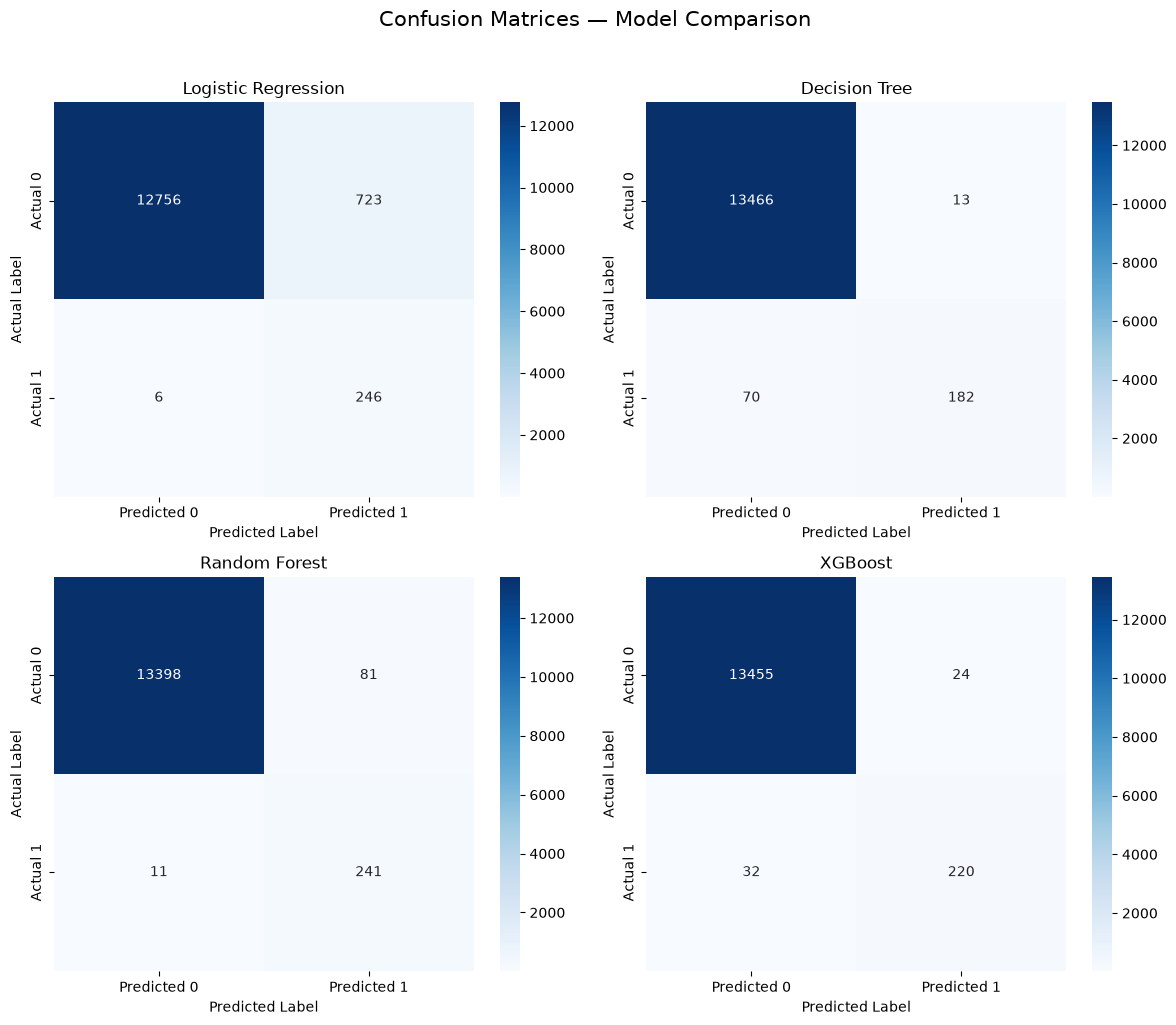

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):

    y_pred = predictions[name]["y_pred"]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1],
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax,
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices — Model Comparison",
    fontsize=15,
    y=1.02,
)
plt.tight_layout()
plt.show()

In [23]:
# # Plot ROC curve

# from sklearn.metrics import roc_curve, roc_auc_score

# fpr, tpr, thresholds = roc_curve(
#     y_test,
#     y_prob,
# )

# auc_score = roc_auc_score(y_test, y_prob)

# plt.figure(figsize=(7, 5))

# plt.plot(
#     fpr,
#     tpr,
#     color="darkorange",
#     linewidth=2,
#     label=f"XGBoost (AUC = {auc_score:.4f})",
# )

# plt.plot(
#     [0, 1],
#     [0, 1],
#     color="navy",
#     linestyle="--",
#     label="Random classifier (AUC = 0.50)",
# )

# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("ROC Curve — XGBoost")
# plt.legend(loc="lower right")
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

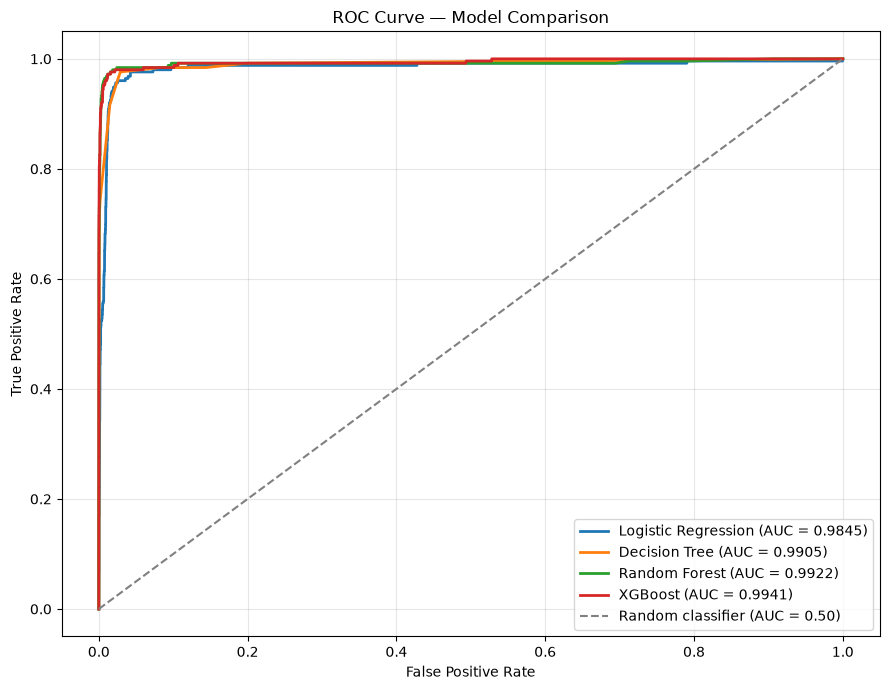

In [24]:
plt.figure(figsize=(9, 7))

for name, model in models.items():

    y_prob = predictions[name]["y_prob"]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob,
    )

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})",
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier (AUC = 0.50)",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Model Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# save the model

joblib.dump(
    {
        "model": xgboost,
        "numerical_cols": numerical_cols,
        "categorical_cols": categorical_cols,
    },
    "xgboost_pipeline.joblib",
)

print("Saved xgboost_pipeline.joblib")

Saved xgboost_pipeline.joblib


In [26]:
# uvicorn app:app --reload
loan_request = {
  "ID": "ID_257244237466267278",
  "customer_id": 257244,
  "country_id": "Kenya",
  "tbl_loan_id": 237466,
  "lender_id": 267278,
  "loan_type": "Type_1",
  "Total_Amount": 16477.0,
  "Total_Amount_to_Repay": 16642.0,
  "disbursement_date": "2022-08-15",
  "due_date": "2022-08-22",
  "duration": 7,
  "New_versus_Repeat": "Repeat Loan",
  "Amount_Funded_By_Lender": 2436.0,
  "Lender_portion_Funded": 0.147842447047399,
  "Lender_portion_to_be_repaid": 2460.0
}